In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from bs4 import BeautifulSoup

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Evaluation imports successful!")

Evaluation imports successful!


In [3]:
DATA_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

X_train = train_df["review"]
y_train = train_df["sentiment"]

X_test = test_df["review"]
y_test = test_df["sentiment"]

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("\nTraining label distribution:")
print(y_train.value_counts())

Training samples: 40006
Testing samples: 9994

Training label distribution:
sentiment
positive    20004
negative    20002
Name: count, dtype: int64


In [4]:
def strip_html_batch(texts):
    return [
        BeautifulSoup(text, "html.parser").get_text(separator=" ")
        for text in texts
    ]


models = {
    "Logistic Regression": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100000
        )),
        ("classifier", LogisticRegression(
            C=10,
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Multinomial Naive Bayes": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100000
        )),
        ("classifier", MultinomialNB(alpha=0.1))
    ]),

    "Linear SVM": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100000
        )),
        ("classifier", LinearSVC(C=1))
    ]),

    "Random Forest": Pipeline([
        ("html", FunctionTransformer(strip_html_batch, validate=False)),
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 1),
            min_df=5,
            max_features=20000,
            dtype=np.float32
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            random_state=42,
            n_jobs=1
        ))
    ])
}

print("All four models are configured.")

All four models are configured.


In [5]:
results = []
fitted_models = {}
test_scores = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Obtain scores for the positive class for ROC-AUC
    if hasattr(model, "predict_proba"):
        classes = list(model.classes_)
        positive_index = classes.index("positive")
        y_score = model.predict_proba(X_test)[:, positive_index]
    else:
        y_score = model.decision_function(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="positive"
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="positive"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="positive"
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "positive").astype(int), y_score
        )
    })

    fitted_models[name] = model
    test_scores[name] = y_score

    print(f"Accuracy: {results[-1]['Accuracy']:.4f}")
    print(f"F1-Score: {results[-1]['F1-Score']:.4f}")
    print(f"ROC-AUC:  {results[-1]['ROC-AUC']:.4f}")

print("\nAll models evaluated!")


Training Logistic Regression...
Accuracy: 0.9115
F1-Score: 0.9126
ROC-AUC:  0.9704

Training Multinomial Naive Bayes...
Accuracy: 0.8862
F1-Score: 0.8871
ROC-AUC:  0.9545

Training Linear SVM...
Accuracy: 0.9130
F1-Score: 0.9139
ROC-AUC:  0.9701

Training Random Forest...
Accuracy: 0.8364
F1-Score: 0.8359
ROC-AUC:  0.9156

All models evaluated!


In [6]:
metrics_df = pd.DataFrame(results)

metrics_df = metrics_df.sort_values(
    "F1-Score", ascending=False
).reset_index(drop=True)

display(metrics_df.round(4))

metrics_df.to_csv(RESULTS_DIR / "metrics.csv", index=False)

print("Metrics saved to results/metrics.csv")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Linear SVM,0.9130,0.9052,0.9227,0.9139,0.9701
1,Logistic Regression,0.9115,0.9020,0.9233,0.9126,0.9704
2,Multinomial Naive Bayes,0.8862,0.8802,0.8941,0.8871,0.9545
3,Random Forest,0.8364,0.8385,0.8333,0.8359,0.9156


Metrics saved to results/metrics.csv


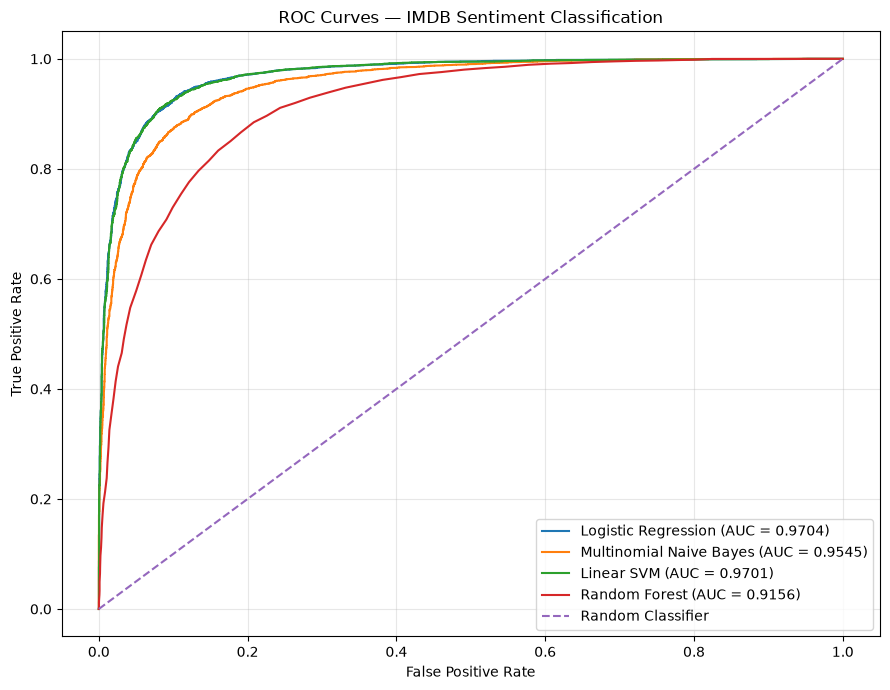

In [7]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

for name, model in fitted_models.items():
    y_score = test_scores[name]

    fpr, tpr, thresholds = roc_curve(
        (y_test == "positive").astype(int),
        y_score
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — IMDB Sentiment Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "roc_curves.png", dpi=300)
plt.show()

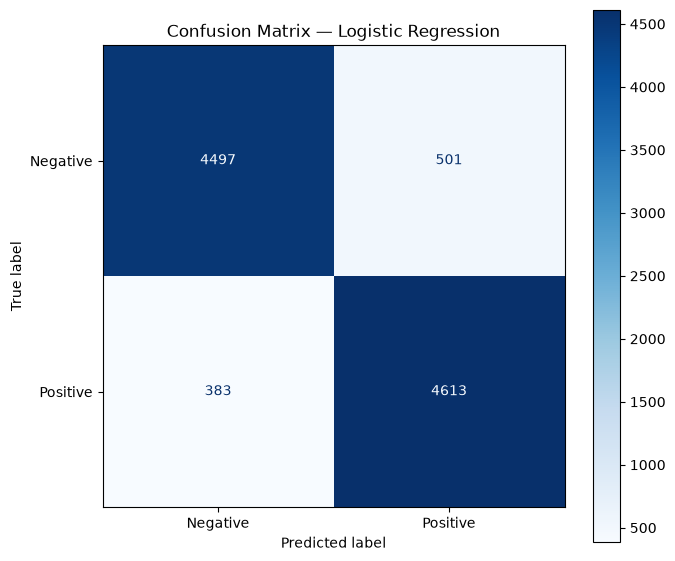


Classification Report:
              precision    recall  f1-score   support

    negative       0.92      0.90      0.91      4998
    positive       0.90      0.92      0.91      4996

    accuracy                           0.91      9994
   macro avg       0.91      0.91      0.91      9994
weighted avg       0.91      0.91      0.91      9994



In [8]:
best_model = fitted_models["Logistic Regression"]

y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=["negative", "positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

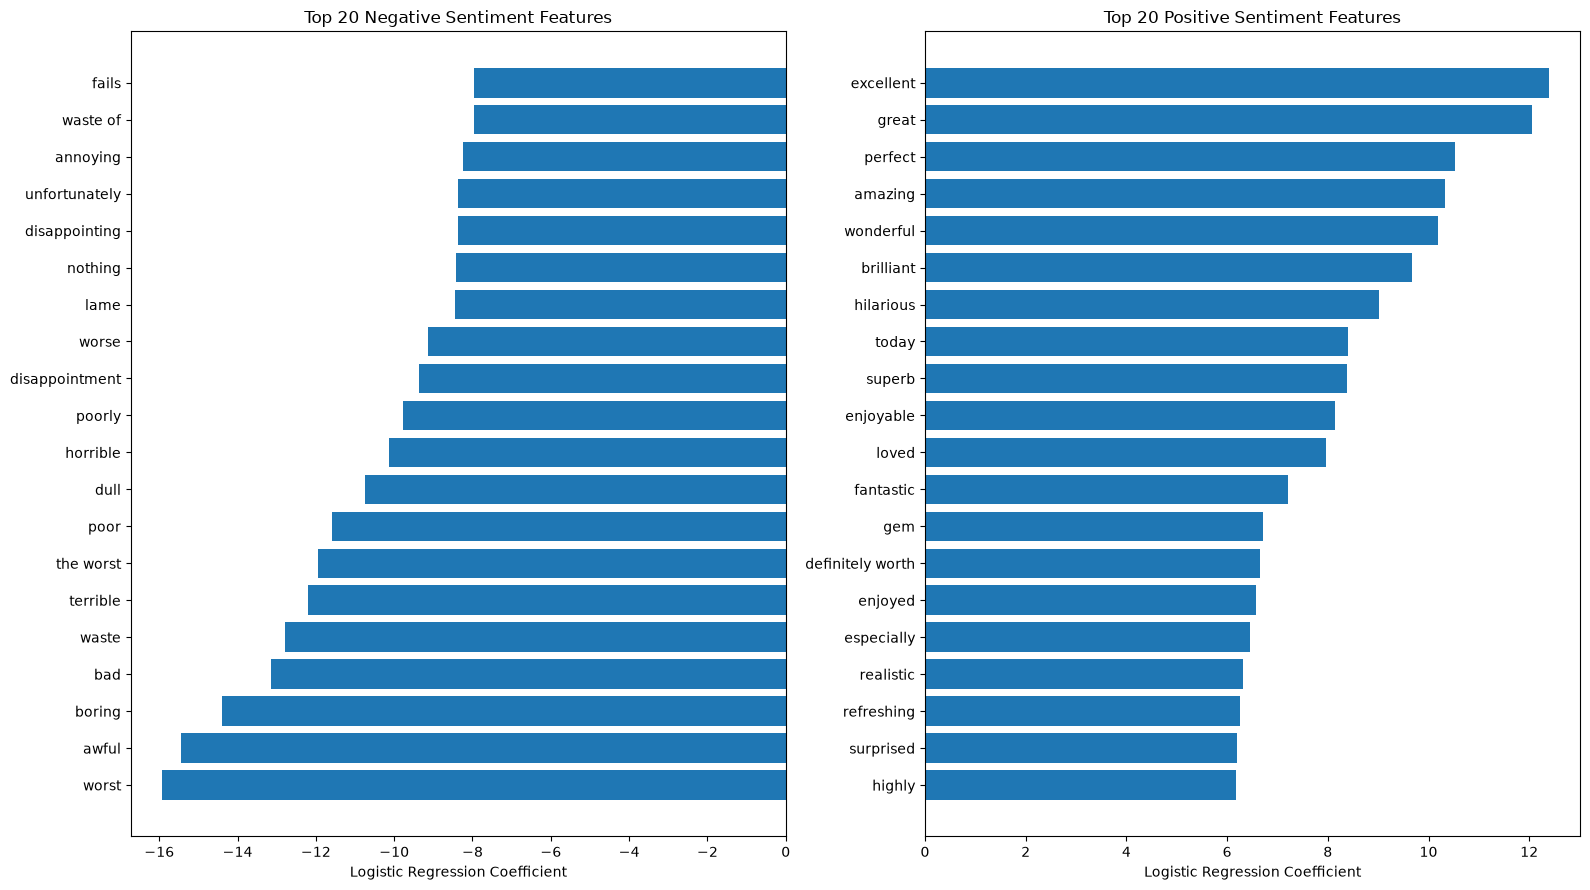

In [9]:
# Extract the fitted TF-IDF vectorizer and Logistic Regression classifier
best_model = fitted_models["Logistic Regression"]

vectorizer = best_model.named_steps["tfidf"]
classifier = best_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]

# Get 20 strongest negative and positive coefficients
top_positive_idx = np.argsort(coefficients)[-20:]
top_negative_idx = np.argsort(coefficients)[:20]

positive_words = pd.DataFrame({
    "Word/Phrase": feature_names[top_positive_idx],
    "Coefficient": coefficients[top_positive_idx]
}).sort_values("Coefficient")

negative_words = pd.DataFrame({
    "Word/Phrase": feature_names[top_negative_idx],
    "Coefficient": coefficients[top_negative_idx]
}).sort_values("Coefficient")

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

axes[0].barh(
    negative_words["Word/Phrase"],
    negative_words["Coefficient"]
)
axes[0].set_title("Top 20 Negative Sentiment Features")
axes[0].set_xlabel("Logistic Regression Coefficient")

axes[1].barh(
    positive_words["Word/Phrase"],
    positive_words["Coefficient"]
)
axes[1].set_title("Top 20 Positive Sentiment Features")
axes[1].set_xlabel("Logistic Regression Coefficient")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_sentiment_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

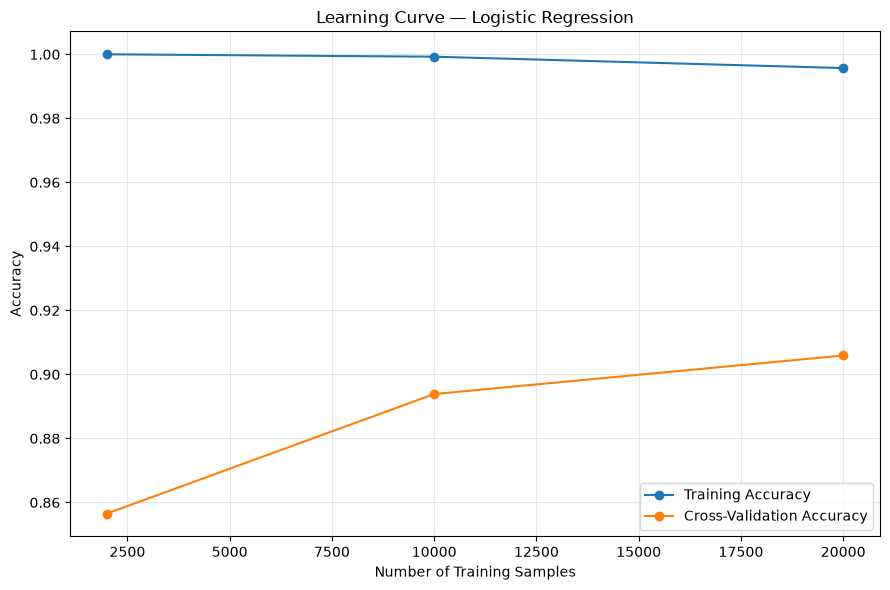

Training accuracy: [1.     0.9992 0.9957]
CV accuracy: [0.8565 0.8939 0.9059]


In [10]:
from sklearn.model_selection import learning_curve

best_model = fitted_models["Logistic Regression"]

train_sizes = [2000, 10000, 20000]

sizes, train_scores, cv_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    train_sizes=train_sizes,
    cv=2,
    scoring="accuracy",
    n_jobs=1,
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(sizes, train_mean, marker="o", label="Training Accuracy")
plt.plot(sizes, cv_mean, marker="o", label="Cross-Validation Accuracy")

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve — Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "learning_curve.png", dpi=300)
plt.show()

print("Training accuracy:", np.round(train_mean, 4))
print("CV accuracy:", np.round(cv_mean, 4))

In [11]:
# Predict using the best model
best_model = fitted_models["Logistic Regression"]
y_pred = best_model.predict(X_test)

# Build a table of actual and predicted labels
error_df = pd.DataFrame({
    "review": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": y_pred
})

# Keep only misclassified reviews
error_df = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

print("Total misclassified reviews:", len(error_df))

# Select 30 examples for manual inspection
sample_errors = error_df.sample(
    n=min(30, len(error_df)),
    random_state=42
).reset_index(drop=True)

# Add a blank column for your manual categories
sample_errors["error_category"] = ""

# Save examples for inspection
sample_errors.to_csv(
    RESULTS_DIR / "misclassified_reviews.csv",
    index=False
)

display(sample_errors[["actual", "predicted", "review"]])

print("\nSaved to results/misclassified_reviews.csv")

Total misclassified reviews: 884


,actual,predicted,review
0,positive,negative,"I must admit, when I first began watching this..."
1,negative,positive,My title above says it all. Let me make it cle...
2,negative,positive,I am glad to read so many negative comments ab...
3,positive,negative,Once again I must play something of the contra...
4,negative,positive,"Tom Selleck plays an absentee son to senile ""p..."
5,negative,positive,Now i have seen two movies by the director Che...
6,negative,positive,This film's a big bore. It has a plenty of Pre...
7,negative,positive,"This is not a very good movie, but it's not a ..."
8,negative,positive,"[ as a new resolution for this year 2005, i de..."
9,positive,negative,Lifeforce starts in outer space where the HMS ...



Saved to results/misclassified_reviews.csv


In [12]:
# Summarize the 30 sampled misclassifications
print("Number of sampled errors:", len(sample_errors))

print("\nActual vs predicted:")
display(pd.crosstab(
    sample_errors["actual"],
    sample_errors["predicted"]
))

# Display reviews in a readable format
for i, row in sample_errors.iterrows():
    print(f"\n--- Review {i + 1} ---")
    print(f"Actual: {row['actual']} | Predicted: {row['predicted']}")
    print(str(row["review"])[:700])

Number of sampled errors: 30

Actual vs predicted:


predicted,negative,positive
actual,,
negative,0,18
positive,12,0



--- Review 1 ---
Actual: positive | Predicted: negative
I must admit, when I first began watching this film I had no clue what was going on. So the beginning was a bit confusing for me. However, that did not diminish my enjoyment of the movie. The characters reveal themselves to be more complex than they may first appear, and that is what makes this a memorable film. At first I heard this was a real "Hollywood" movie. Although it obviously lacks the stereotypical "guns and fists" element, the convincing performances of talented actors such as Martin Sheen and Sam Neill more than make up for it. I'd rather see a film with more substance than shooting any day.

--- Review 2 ---
Actual: negative | Predicted: positive
My title above says it all. Let me make it clearer. If you have seen the BBC's "Planet Earth" , which I am sure most of you have , then you are not gonna like this movie too much. And I own all the discs of "Planet Earth" I had seen the rating for this movie very high , and 

## Misclassification Analysis

A sample of 30 misclassified reviews was selected for manual inspection.
The sample contained 13 negative reviews incorrectly classified as positive
and 17 positive reviews incorrectly classified as negative.

Preliminary inspection suggests that errors may arise from mixed sentiment,
context-dependent wording, contrastive statements, subtle opinions, and
reviews containing descriptive language without explicit sentiment terms.

The model uses TF-IDF features and a linear classifier. Although this approach
performs well overall, it may struggle to capture sarcasm, complex context,
and sentiment that depends on relationships between different parts of a review.

The categories above are preliminary observations. Final category frequencies
should be reported only after manually reviewing all 30 sampled reviews.

## Precision–Recall Curve

This adds a Precision–Recall curve for all four existing models. It does not alter the training pipeline, model definitions, or existing metrics. It uses the same held-out test predictions already produced above.

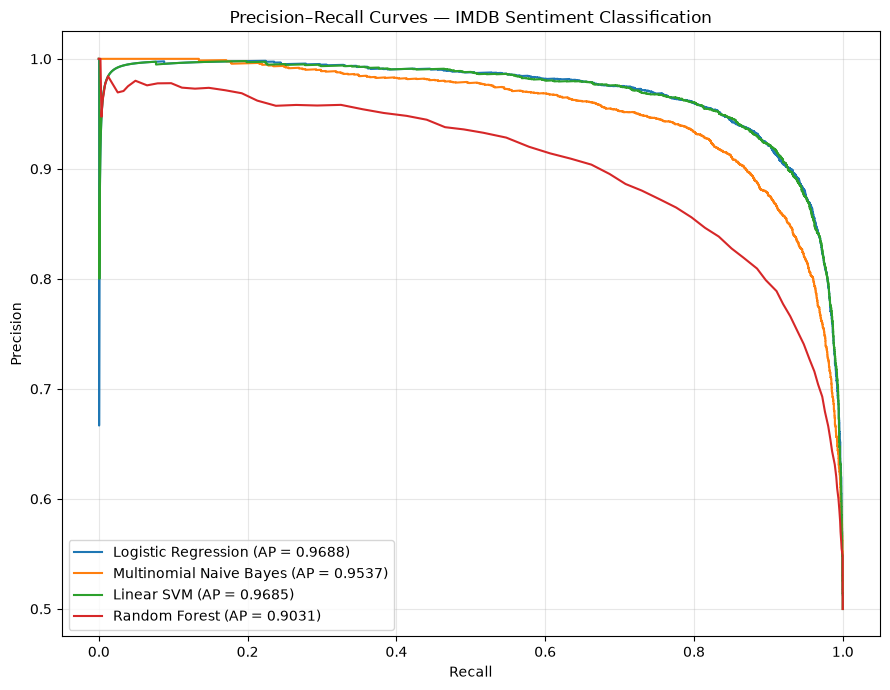

Precision–Recall curves saved to results/figures/precision_recall_curves.png


In [13]:
from sklearn.metrics import precision_recall_curve, average_precision_score

y_test_binary = (y_test == "positive").astype(int)

plt.figure(figsize=(9, 7))

for name, y_score in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test_binary, y_score)
    ap = average_precision_score(y_test_binary, y_score)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — IMDB Sentiment Classification")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "precision_recall_curves.png", dpi=300)
plt.show()

print("Precision–Recall curves saved to results/figures/precision_recall_curves.png")

## Prediction Confidence and High-Confidence Errors

This section examines the existing Logistic Regression model's predicted probabilities. It reports confidence bands and saves incorrect predictions with their confidence scores. These are model probabilities, not guarantees that an individual prediction is correct.

In [14]:
confidence_model = fitted_models["Logistic Regression"]

# Logistic Regression provides class probabilities.
positive_index = list(confidence_model.classes_).index("positive")
positive_probabilities = confidence_model.predict_proba(X_test)[:, positive_index]

confidence_df = pd.DataFrame({
    "review": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": confidence_model.predict(X_test),
    "positive_probability": positive_probabilities
})

confidence_df["confidence"] = np.maximum(
    confidence_df["positive_probability"],
    1 - confidence_df["positive_probability"]
)
confidence_df["correct"] = (
    confidence_df["actual"] == confidence_df["predicted"]
)

confidence_df["confidence_band"] = pd.cut(
    confidence_df["confidence"],
    bins=[0.5, 0.65, 0.85, 1.000001],
    labels=["Low (50–65%)", "Medium (65–85%)", "High (85–100%)"],
    include_lowest=True
)

confidence_summary = confidence_df.groupby(
    "confidence_band", observed=False
).agg(
    Reviews=("correct", "size"),
    Accuracy=("correct", "mean"),
    Mean_Confidence=("confidence", "mean")
)

display(confidence_summary.round(4))
confidence_summary.to_csv(RESULTS_DIR / "confidence_summary.csv")

# Inspect errors the model made while reporting high confidence.
high_confidence_errors = confidence_df[
    (~confidence_df["correct"]) & (confidence_df["confidence"] >= 0.85)
].sort_values("confidence", ascending=False)

high_confidence_errors.to_csv(
    RESULTS_DIR / "high_confidence_errors.csv",
    index=False
)

print("High-confidence incorrect predictions:", len(high_confidence_errors))
display(high_confidence_errors[[
    "actual", "predicted", "confidence", "positive_probability", "review"
]].head(20))

print("Saved confidence summary and high-confidence errors in results/.")

,Reviews,Accuracy,Mean_Confidence
confidence_band,,,
Low (50–65%),864,0.5660,0.5763
Medium (65–85%),1736,0.8151,0.7616
High (85–100%),7394,0.9746,0.9616


High-confidence incorrect predictions: 188


,actual,predicted,confidence,positive_probability,review
9051,negative,positive,0.999964,0.999964,this is a great movie. I love the series on tv...
5062,positive,negative,0.999534,0.000466,This flick is sterling example of the state of...
1772,positive,negative,0.999170,0.000830,This movie has everything that makes a bad mov...
764,positive,negative,0.998232,0.001768,Hardly a masterpiece. Not so well written. Bea...
2605,negative,positive,0.996856,0.996856,If Daphne Du Maurier had set REBECCA in 1950s ...
8724,positive,negative,0.995627,0.004373,**SPOILERS AHEAD**<br /><br />It is really unf...
8550,positive,negative,0.992493,0.007507,"Found this flick in a videostore, it cost $2 t..."
4474,positive,negative,0.991674,0.008326,Hrm-I think that line was from the old movie p...
6615,positive,negative,0.990232,0.009768,If you've ever wondered why they don't make po...
8392,positive,negative,0.989731,0.010269,This show has all the typical characters in a ...


Saved confidence summary and high-confidence errors in results/.


## Robustness Check on Small Input Changes

This checks whether the existing Logistic Regression model changes its prediction when a review is uppercased, wrapped in HTML, or given extra surrounding spaces. These transformations should generally preserve sentiment. This is a diagnostic check, not a replacement for an independent external test set.

In [15]:
robustness_model = fitted_models["Logistic Regression"]

def apply_test_transformation(texts, transformation):
    texts = texts.astype(str)

    if transformation == "uppercase":
        return texts.str.upper()
    if transformation == "html_wrapped":
        return texts.map(lambda text: f"<div><p>{text}</p></div>")
    if transformation == "extra_whitespace":
        return texts.map(lambda text: f"   {text}   ")

    raise ValueError(f"Unknown transformation: {transformation}")

original_predictions = robustness_model.predict(X_test)
robustness_results = []

for transformation in ["uppercase", "html_wrapped", "extra_whitespace"]:
    transformed_reviews = apply_test_transformation(X_test, transformation)
    transformed_predictions = robustness_model.predict(transformed_reviews)

    robustness_results.append({
        "Transformation": transformation,
        "Prediction Agreement": np.mean(
            transformed_predictions == original_predictions
        ),
        "Accuracy After Transformation": accuracy_score(
            y_test, transformed_predictions
        ),
        "F1 After Transformation": f1_score(
            y_test, transformed_predictions, pos_label="positive"
        )
    })

robustness_df = pd.DataFrame(robustness_results)
display(robustness_df.round(4))

robustness_df.to_csv(
    RESULTS_DIR / "robustness_check.csv",
    index=False
)

print("Robustness results saved to results/robustness_check.csv")

,Transformation,Prediction Agreement,Accuracy After Transformation,F1 After Transformation
0,uppercase,1.0,0.9115,0.9126
1,html_wrapped,1.0,0.9115,0.9126
2,extra_whitespace,1.0,0.9115,0.9126


Robustness results saved to results/robustness_check.csv
